# Random_Numbers

file about the first assignemnt pdf


In [38]:
# Room 1
def LCG(seed, a, c, m):
    """Linear Congruential Generator (LCG) implementation."""
    seed = (seed * a + c) % m
    return seed

seed = 7
sequence = []

def find_cycle(seed, a, c, m):
    seen = {}            # state -> step where it first appeared
    states = []
    x, n = seed, 0
    while x not in seen:
        seen[x] = n
        states.append(x)
        x = LCG(x, a, c, m)
        n += 1
    mu = seen[x]         # tail length = index where the cycle starts
    return states, x, n - mu, mu

states, repeated, cycle_len, tail_len = find_cycle(7, 1103515245, 12345, 65536)
print("First 12 states:", states[:12])
print("Repeated state:", repeated)
print("Cycle length:", cycle_len)
print("Initial non-repeating segment:", "yes, length %d" % tail_len if tail_len > 0 else "no")


First 12 states: [7, 21812, 20317, 20690, 38307, 37024, 33881, 43038, 59647, 5836, 3349, 10282]
Repeated state: 7
Cycle length: 65536
Initial non-repeating segment: no


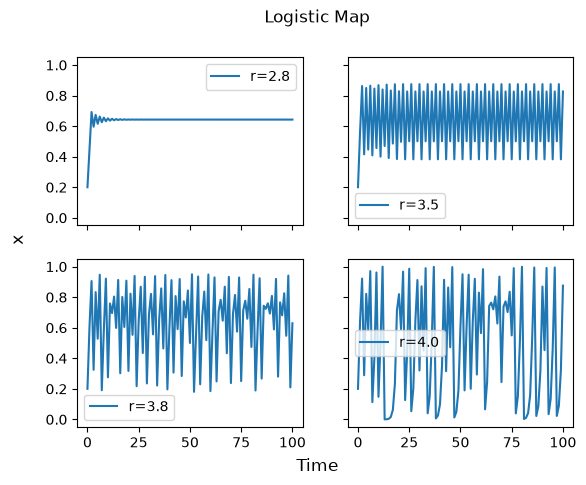

In [26]:
# Room 2
import numpy as np
import matplotlib.pyplot as plt

#standard logistic formula
r = [3.5]
x0 = 0.2
n = 100

def logistic_map(r, x0, n):
    x = np.empty(n+1)
    x[0] = x0
    for i in range(n):
        x[i+1] = r * x[i] * (1 - x[i])
    return x

x_axis = logistic_map(r[0], x0, n)
r_values = [2.8, 3.5, 3.8, 4.0]
fig, ax = plt.subplots(2, 2, sharex=True, sharey=True)
for a, r_i in zip(ax.flat, r_values):
    a.plot(range(n+1), logistic_map(r_i, x0, n), label=f'r={r_i}')
    a.legend()
fig.supxlabel('Time')
fig.supylabel('x')
fig.suptitle('Logistic Map')
plt.show()


In [27]:
def cycle_length(r, x0, transient=1000, max_period=64, tol=1e-6):
    """Length of the repeating cycle once the initial behaviour has settled."""
    x = logistic_map(r, x0, transient)[-1]   # skip the transient
    start = x
    for p in range(1, max_period + 1):
        x = r * x * (1 - x)
        if abs(x - start) < tol:              # back at the start -> one full oscillation
            return p
    return None                               # no cycle found (e.g. chaos)

key_D = cycle_length(r[0], x0)
print("Key D (cycle length at r=3.5):", key_D)
print("Values in one cycle:", np.round(logistic_map(r[0], x0, 1000 + key_D)[-key_D:], 4))

Key D (cycle length at r=3.5): 4
Values in one cycle: [0.5009 0.875  0.3828 0.8269]


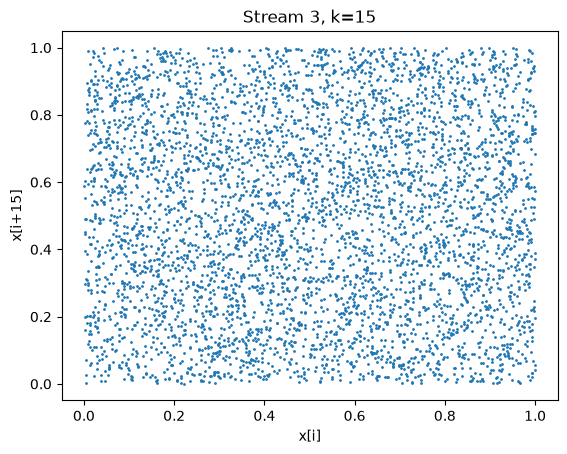

In [36]:
# Room 3

import pandas as pd

df = pd.read_csv("streams.csv")

stream = '3'   # column heading: '3', '6', '9' or '12'
k = 15        # lag

x = df[stream].to_numpy()
plt.scatter(x[:-k], x[k:], s=1)
plt.xlabel('x[i]')
plt.ylabel(f'x[i+{k}]')
plt.title(f'Stream {stream}, k={k}')
plt.show()


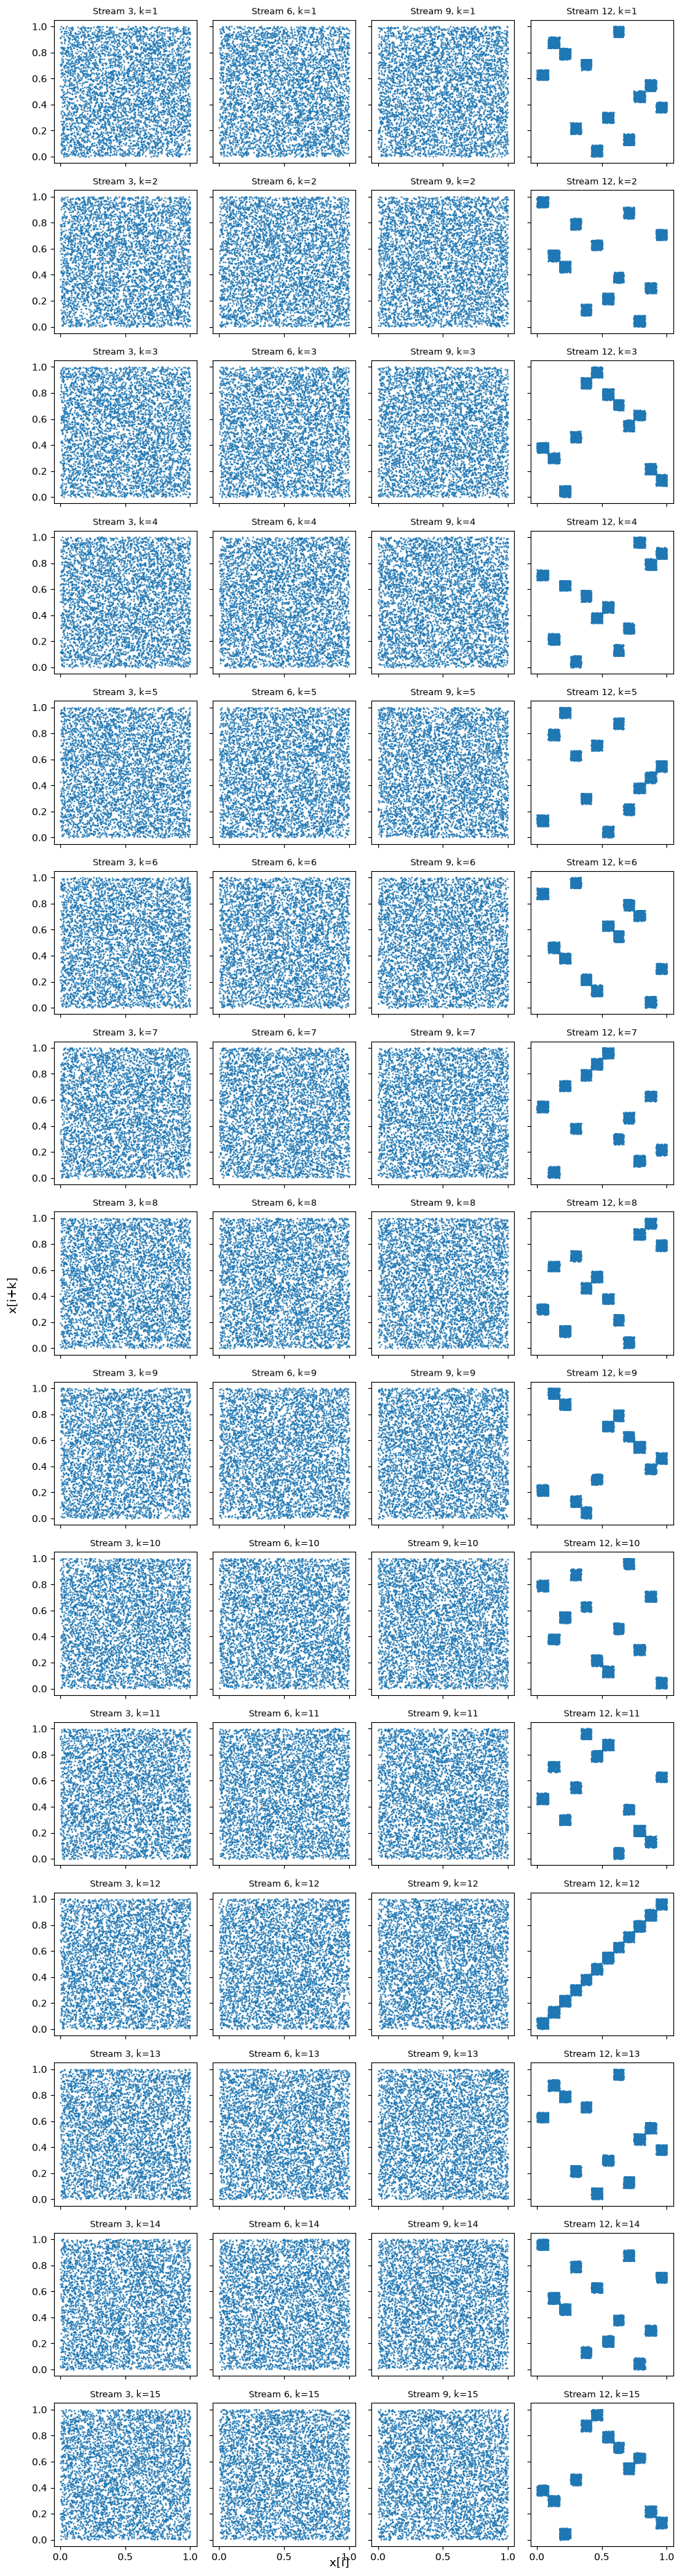

In [37]:
# x[i] against x[i+k] for every stream (columns) and k = 1..15 (rows)
ks = range(1, 16)
fig, ax = plt.subplots(len(ks), len(df.columns), figsize=(10, 2.5 * len(ks)), sharex=True, sharey=True)
for row, k in enumerate(ks):
    for col, stream in enumerate(df.columns):
        x = df[stream].to_numpy()
        ax[row, col].scatter(x[:-k], x[k:], s=0.5)
        ax[row, col].set_title(f'Stream {stream}, k={k}', fontsize=9)
fig.supxlabel('x[i]')
fig.supylabel('x[i+k]')
fig.tight_layout()
plt.show()


In [ ]:
# Room 4
from fractions import Fraction

M = cycle_len   # Room 1: number of distinct states in the cycle (65536)
D = key_D       # Room 2: cycle length at r=3.5 (4)
T = 12          # Room 3: column heading of the counterfeit stream

LOCK = range(M)   # integers 0..M-1, all equally likely

Sensor_A = [x % D == 0 for x in LOCK]
Sensor_B = [x < T for x in LOCK]

B = [x for x in LOCK if Sensor_B[x]]
A_and_B = [x for x in LOCK if Sensor_A[x] and Sensor_B[x]]

# P(A|B) = P(A and B) / P(B); the 1/M in both cancels, leaving a ratio of counts
probability = Fraction(len(A_and_B), len(B))
print("M =", M, " D =", D, " T =", T)
print("Outcomes that activate B:", B)
print("Outcomes that activate A and B:", A_and_B)
print(f"P(A|B) = P(A and B) / P(B) = {len(A_and_B)}/{len(B)} = {probability}")
print("Unlock code:", str(float(probability)).replace('.', ''))
